# =========================================================
# 3) BACKTESTER
# Signals (computed at bar t):
#   LongEntrySignal TRUE if:
#       OPEN(t) > KC_Upper(20,1.5, shift=1)   [KC condition is duplicated in SQX, ignore duplication]
#       RSI(50, shift=4) < RSI(50, shift=3)
#   ShortEntrySignal TRUE if:
#       OPEN(t) < KC_Lower(20,1.5, shift=1)
#       RSI(50, shift=4) > RSI(50, shift=3)
#
# Entry STOP orders:
#   BuyStop  = Highest(CLOSE, 20, shift=3) + 2.4 * ATR(40, shift=3)
#   SellStop = Lowest (CLOSE, 20, shift=3) - 2.4 * ATR(40, shift=3)
#   Pending expiration = 2 bars
#
# Exit:
#   SL_dist = 2.8 * ATR(20, shift=1)
#   TP_dist = 4.2 * ATR(25, shift=1)
#   ExitAfterBars = 40
#
# MM:
#   Risk Fixed % Balance = 1%
# =========================================================

⏳ Downloading ETHUSDT 1h...
✅ Data ready: 18791 bars after indicator warmup.
🚀 Running backtest...

🎯 KC(20,1.5) + RSI(50,CLOSE slope) + STOP(Hi/Lo Close 20) + ATR40 buffer
  Final Equity: 15114.632340
  Total Return: 0.511463
 CAGR (approx): 0.212807
  Max Drawdown: -0.092387
        Sharpe: 1.592579
        Trades: 255
       Winrate: 0.474510
 Profit Factor: 1.352511


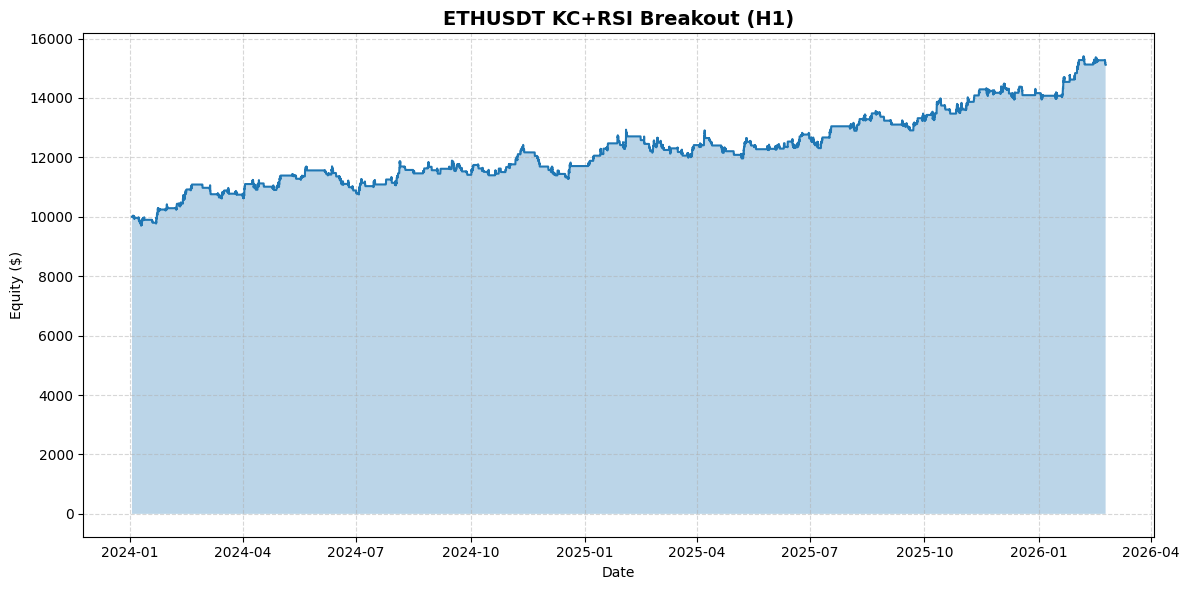


📊 Trades (first 12):
          Exit Time  Type       Entry        Exit  Qty         PnL      Reason      Balance
2024-01-05 06:00:00 SHORT 2223.790000 2255.340000 1.22  -38.491000   Time Exit  9961.509000
2024-01-08 07:00:00 SHORT 2191.178229 2229.859515 2.57  -99.410905   Stop Loss  9862.098095
2024-01-09 12:00:00  LONG 2335.980000 2279.662593 1.75  -98.555462   Stop Loss  9763.542633
2024-01-10 21:00:00  LONG 2398.640000 2512.385425 1.20  136.494510 Take Profit  9900.037143
2024-01-12 17:00:00  LONG 2606.420000 2603.050000 0.82   -2.763400   Time Exit  9897.273743
2024-01-19 10:00:00 SHORT 2439.500000 2490.419589 1.94  -98.784003   Stop Loss  9798.489741
2024-01-22 10:00:00 SHORT 2429.171599 2383.436027 3.30  150.927387 Take Profit  9949.417128
2024-01-22 19:00:00 SHORT 2379.202611 2318.654751 2.37  143.498426 Take Profit 10092.915554
2024-01-23 09:00:00 SHORT 2327.169963 2242.468720 1.65  139.757051 Take Profit 10232.672605
2024-01-25 03:00:00 SHORT 2223.350000 2216.880000 1.57   1

In [1]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# =========================================================
# 1) FETCH BINANCE DATA
# =========================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Downloading {symbol} {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200:
                print("Fetch error:", r.status_code, r.text)
                break

            data = r.json()
            if not data:
                break

            all_klines.extend(data)
            start_time = data[-1][0] + 1
            time.sleep(0.05)

        except Exception as e:
            print("Fetch exception:", e)
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# =========================================================
# 2) INDICATORS
# Strategy requires:
#   - KC(20, dev=1.5), compare OPEN(t) to KC shift=1
#   - RSI(50) on CLOSE, slope check: RSI(shift=4) < RSI(shift=3) for long
#   - Entry: Highest/Lowest CLOSE window=20, shift=3
#   - Entry buffer: ATR(40) shift=3, mult=2.4
#   - SL: 2.8 * ATR(20) shift=1
#   - TP: 4.2 * ATR(25) shift=1
# =========================================================
def calculate_indicators(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    # --- True Range ---
    prev_close = data["Close"].shift(1)
    tr = pd.concat([
        (data["High"] - data["Low"]),
        (data["High"] - prev_close).abs(),
        (data["Low"] - prev_close).abs(),
    ], axis=1).max(axis=1)
    data["TR"] = tr

    # --- Wilder ATR (RMA) ---
    def calc_atr(tr_series: pd.Series, period: int) -> pd.Series:
        return tr_series.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data["ATR_20"] = calc_atr(data["TR"], 20)
    data["ATR_25"] = calc_atr(data["TR"], 25)
    data["ATR_40"] = calc_atr(data["TR"], 40)

    # --- RSI (simple rolling mean version; matches the style of your earlier template) ---
    def calc_rsi(series: pd.Series, period: int) -> pd.Series:
        delta = series.diff()
        gain = delta.where(delta > 0, 0.0).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0.0)).rolling(window=period).mean()
        rs = gain / loss
        return 100 - (100 / (1 + rs))

    data["RSI_50_Close"] = calc_rsi(data["Close"], 50)

    # --- Keltner Channel (20, dev=1.5) ---
    # Center: EMA(Close, 20)
    # Band: EMA +/- dev * ATR(20) (Wilder ATR)
    ema_20 = data["Close"].ewm(span=20, adjust=False).mean()
    data["KC_Upper_20_1p5"] = ema_20 + 1.5 * data["ATR_20"]
    data["KC_Lower_20_1p5"] = ema_20 - 1.5 * data["ATR_20"]

    # --- Highest/Lowest Close window=20 ---
    data["Highest_Close_20"] = data["Close"].rolling(window=20).max()
    data["Lowest_Close_20"] = data["Close"].rolling(window=20).min()

    # Clean rows with NaNs from rolling/ATR/RSI warmup
    data.dropna(inplace=True)
    return data


# =========================================================
# 3) BACKTESTER
# Signals (computed at bar t):
#   LongEntrySignal TRUE if:
#       OPEN(t) > KC_Upper(20,1.5, shift=1)   [KC condition is duplicated in SQX, ignore duplication]
#       RSI(50, shift=4) < RSI(50, shift=3)
#   ShortEntrySignal TRUE if:
#       OPEN(t) < KC_Lower(20,1.5, shift=1)
#       RSI(50, shift=4) > RSI(50, shift=3)
#
# Entry STOP orders:
#   BuyStop  = Highest(CLOSE, 20, shift=3) + 2.4 * ATR(40, shift=3)
#   SellStop = Lowest (CLOSE, 20, shift=3) - 2.4 * ATR(40, shift=3)
#   Pending expiration = 2 bars
#
# Exit:
#   SL_dist = 2.8 * ATR(20, shift=1)
#   TP_dist = 4.2 * ATR(25, shift=1)
#   ExitAfterBars = 40
#
# MM:
#   Risk Fixed % Balance = 1%
# =========================================================
class KC_RSI_Breakout_Backtester:
    def __init__(self, df: pd.DataFrame, initial_balance: float = 10000.0):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.equity_curve = []
        self.trades = []

        # Position state
        self.position = None  # "LONG" / "SHORT" / None
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.qty = 0.0
        self.entry_bar_idx = 0

        # Pending stop order state
        self.pending_order = None

        # Params (from your spec)
        self.kc_period = 20
        self.kc_dev = 1.5

        self.rsi_period = 50

        self.period_param = 20
        self.hl_shift = 3

        self.atr_entry_period = 40
        self.atr_entry_shift = 3
        self.price_entry_mult = 2.4

        self.sl_coef = 2.8
        self.tp_coef = 4.2

        self.exit_after_bars = 40
        self.pending_expiration = 2

        # MM
        self.risk_pct = 0.01
        self.mm_max_lots = 100.0
        self.mm_decimals = 2

    def run(self):
        idxs = self.df.index

        for i in range(len(self.df)):
            t = idxs[i]
            bar = self.df.iloc[i]

            # -------------------------------------------------
            # A) Manage open position (SL/TP/Time exit)
            # -------------------------------------------------
            if self.position is not None:
                held = i - self.entry_bar_idx

                if held >= self.exit_after_bars:
                    self.close_position(bar["Close"], t, "Time Exit")
                    self.append_equity(t)
                    continue

                if self.position == "LONG":
                    if bar["Low"] <= self.sl:
                        self.close_position(self.sl, t, "Stop Loss")
                        self.append_equity(t)
                        continue
                    if bar["High"] >= self.tp:
                        self.close_position(self.tp, t, "Take Profit")
                        self.append_equity(t)
                        continue

                if self.position == "SHORT":
                    if bar["High"] >= self.sl:
                        self.close_position(self.sl, t, "Stop Loss")
                        self.append_equity(t)
                        continue
                    if bar["Low"] <= self.tp:
                        self.close_position(self.tp, t, "Take Profit")
                        self.append_equity(t)
                        continue

            # -------------------------------------------------
            # B) Manage pending order (expiration / fill)
            # -------------------------------------------------
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order["expire_idx"]:
                    self.pending_order = None
                else:
                    p = self.pending_order["price"]
                    if self.pending_order["type"] == "BUY_STOP":
                        if bar["High"] >= p:
                            fill = max(p, bar["Open"])  # conservative
                            self.open_position(
                                "LONG", fill, i,
                                self.pending_order["sl_dist"],
                                self.pending_order["tp_dist"]
                            )
                            self.pending_order = None
                    elif self.pending_order["type"] == "SELL_STOP":
                        if bar["Low"] <= p:
                            fill = min(p, bar["Open"])  # conservative
                            self.open_position(
                                "SHORT", fill, i,
                                self.pending_order["sl_dist"],
                                self.pending_order["tp_dist"]
                            )
                            self.pending_order = None

            # -------------------------------------------------
            # C) If flat & no pending -> compute signal & place pending
            # Need RSI(shift=4) and RSI(shift=3), KC shift=1, HL/ATR entry shift=3
            # => minimal i >= 4
            # -------------------------------------------------
            if self.position is None and self.pending_order is None:
                if i < 4:
                    self.append_equity(t)
                    continue

                open_0 = bar["Open"]

                # KC shift=1
                kc_up_1 = self.df.iloc[i-1]["KC_Upper_20_1p5"]
                kc_lo_1 = self.df.iloc[i-1]["KC_Lower_20_1p5"]

                # RSI slope check: shift=4 vs shift=3
                rsi_4 = self.df.iloc[i-4]["RSI_50_Close"]
                rsi_3 = self.df.iloc[i-3]["RSI_50_Close"]

                long_signal = (open_0 > kc_up_1) and (rsi_4 < rsi_3)
                short_signal = (open_0 < kc_lo_1) and (rsi_4 > rsi_3)

                if not long_signal and not short_signal:
                    self.append_equity(t)
                    continue

                # Entry: Highest/Lowest Close window=20, shift=3 -> use i-3 value
                highest_close_3 = self.df.iloc[i-3]["Highest_Close_20"]
                lowest_close_3 = self.df.iloc[i-3]["Lowest_Close_20"]

                # Entry buffer: ATR(40) shift=3 -> use i-3 value
                atr40_3 = self.df.iloc[i-3]["ATR_40"]

                # SL/TP distances use ATR(20/25) shift=1 -> use i-1 value
                atr20_1 = self.df.iloc[i-1]["ATR_20"]
                atr25_1 = self.df.iloc[i-1]["ATR_25"]
                sl_dist = self.sl_coef * atr20_1
                tp_dist = self.tp_coef * atr25_1

                if long_signal:
                    entry = highest_close_3 + self.price_entry_mult * atr40_3
                    self.pending_order = {
                        "type": "BUY_STOP",
                        "price": float(entry),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration
                    }
                elif short_signal and (not long_signal):
                    entry = lowest_close_3 - self.price_entry_mult * atr40_3
                    self.pending_order = {
                        "type": "SELL_STOP",
                        "price": float(entry),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration
                    }

            # -------------------------------------------------
            # D) Append equity (mark-to-market)
            # -------------------------------------------------
            self.append_equity(t)

    def append_equity(self, t):
        close_px = self.df.loc[t, "Close"]
        mtm = self.balance

        if self.position == "LONG":
            mtm += (close_px - self.entry_price) * self.qty
        elif self.position == "SHORT":
            mtm += (self.entry_price - close_px) * self.qty

        self.equity_curve.append({"time": t, "equity": mtm})

    def open_position(self, pos_type: str, price: float, bar_idx: int, sl_dist: float, tp_dist: float):
        self.position = pos_type
        self.entry_price = float(price)
        self.entry_bar_idx = int(bar_idx)

        if pos_type == "LONG":
            self.sl = self.entry_price - sl_dist
            self.tp = self.entry_price + tp_dist
        else:
            self.sl = self.entry_price + sl_dist
            self.tp = self.entry_price - tp_dist

        # Risk Fixed % Balance sizing (approx)
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(self.entry_price - self.sl)
        qty = (risk_amount / sl_distance) if sl_distance > 0 else 0.0

        qty = min(qty, self.mm_max_lots)
        qty = np.floor(qty * (10 ** self.mm_decimals)) / (10 ** self.mm_decimals)
        self.qty = float(qty)

    def close_position(self, price: float, t, reason: str):
        price = float(price)

        if self.position == "LONG":
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty

        self.balance += pnl

        self.trades.append({
            "Exit Time": t,
            "Type": self.position,
            "Entry": self.entry_price,
            "Exit": price,
            "Qty": self.qty,
            "PnL": pnl,
            "Reason": reason,
            "Balance": self.balance
        })

        self.position = None
        self.qty = 0.0
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.entry_bar_idx = 0


# =========================================================
# 4) METRICS + PLOT
# =========================================================
def calculate_metrics(trades_df: pd.DataFrame, equity_data, initial_balance: float):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = float(eq_df["equity"].iloc[-1])
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_balance) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    dd = (eq_df["equity"] - running_max) / running_max
    max_dd = float(dd.min())

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["returns"].mean()
    std_ret = eq_df["returns"].std()

    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret and std_ret != 0 else 0.0

    total_trades = len(trades_df)
    win_trades = int((trades_df["PnL"] > 0).sum()) if total_trades > 0 else 0
    win_rate = win_trades / total_trades if total_trades > 0 else 0.0

    gross_profit = float(trades_df.loc[trades_df["PnL"] > 0, "PnL"].sum()) if total_trades > 0 else 0.0
    gross_loss = float(abs(trades_df.loc[trades_df["PnL"] < 0, "PnL"].sum())) if total_trades > 0 else 0.0
    profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": float(total_return),
        "CAGR (approx)": float(cagr),
        "Max Drawdown": max_dd,
        "Sharpe": float(sharpe),
        "Trades": int(total_trades),
        "Winrate": float(win_rate),
        "Profit Factor": float(profit_factor),
        "equity_df": eq_df
    }

def print_report_and_plot(metrics, symbol: str):
    print("\n" + "=" * 72)
    print("🎯 KC(20,1.5) + RSI(50,CLOSE slope) + STOP(Hi/Lo Close 20) + ATR40 buffer")
    print("=" * 72)
    for k in ["Final Equity", "Total Return", "CAGR (approx)", "Max Drawdown", "Sharpe", "Trades", "Winrate", "Profit Factor"]:
        v = metrics[k]
        if isinstance(v, float):
            print(f"{k:>14}: {v:.6f}")
        else:
            print(f"{k:>14}: {v}")
    print("=" * 72)

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.3)
    plt.title(f"{symbol} KC+RSI Breakout (H1)", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# =========================================================
# 5) MAIN
# =========================================================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"

    # Change these dates as you like
    start_date = "01/01/2024"
    end_date = "23/02/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)
    if df_raw.empty or len(df_raw) < 500:
        print("❌ Not enough data / download failed.")
        raise SystemExit

    df = calculate_indicators(df_raw)
    print(f"✅ Data ready: {len(df)} bars after indicator warmup.")

    bt = KC_RSI_Breakout_Backtester(df, initial_balance=10000.0)
    print("🚀 Running backtest...")
    bt.run()

    trades_df = pd.DataFrame(bt.trades)
    if trades_df.empty:
        print("⚠️ No trades generated.")
        raise SystemExit

    metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
    print_report_and_plot(metrics, symbol)

    print("\n📊 Trades (first 12):")
    print(trades_df.head(12).to_string(index=False))

    print("\n📌 Exit reasons:")
    print(trades_df["Reason"].value_counts().to_string())
